In [4]:
import matplotlib.pyplot as plt
from skimage import data, img_as_float
from scipy.signal import convolve2d, wiener
from skimage.restoration import denoise_bilateral
import numpy as np
from skimage import io
from scipy.ndimage import uniform_filter, gaussian_filter, median_filter, minimum_filter, maximum_filter, generic_filter
from skimage.util import random_noise

In [8]:
# Load the  image
my_img = io.imread("space.jpg")
image = img_as_float(my_img)
image = img_as_float(data.astronaut())


g:\SAKSHAM RAJ\ARSD\Semester - 7\DIP\Practical\allPracticals\.venv\Lib\site-packages\scipy\signal\_signaltools.py:1752: RuntimeWarning: divide by zero encountered in divide
  res *= (1 - noise / lVar)
g:\SAKSHAM RAJ\ARSD\Semester - 7\DIP\Practical\allPracticals\.venv\Lib\site-packages\scipy\signal\_signaltools.py:1752: RuntimeWarning: invalid value encountered in multiply
  res *= (1 - noise / lVar)


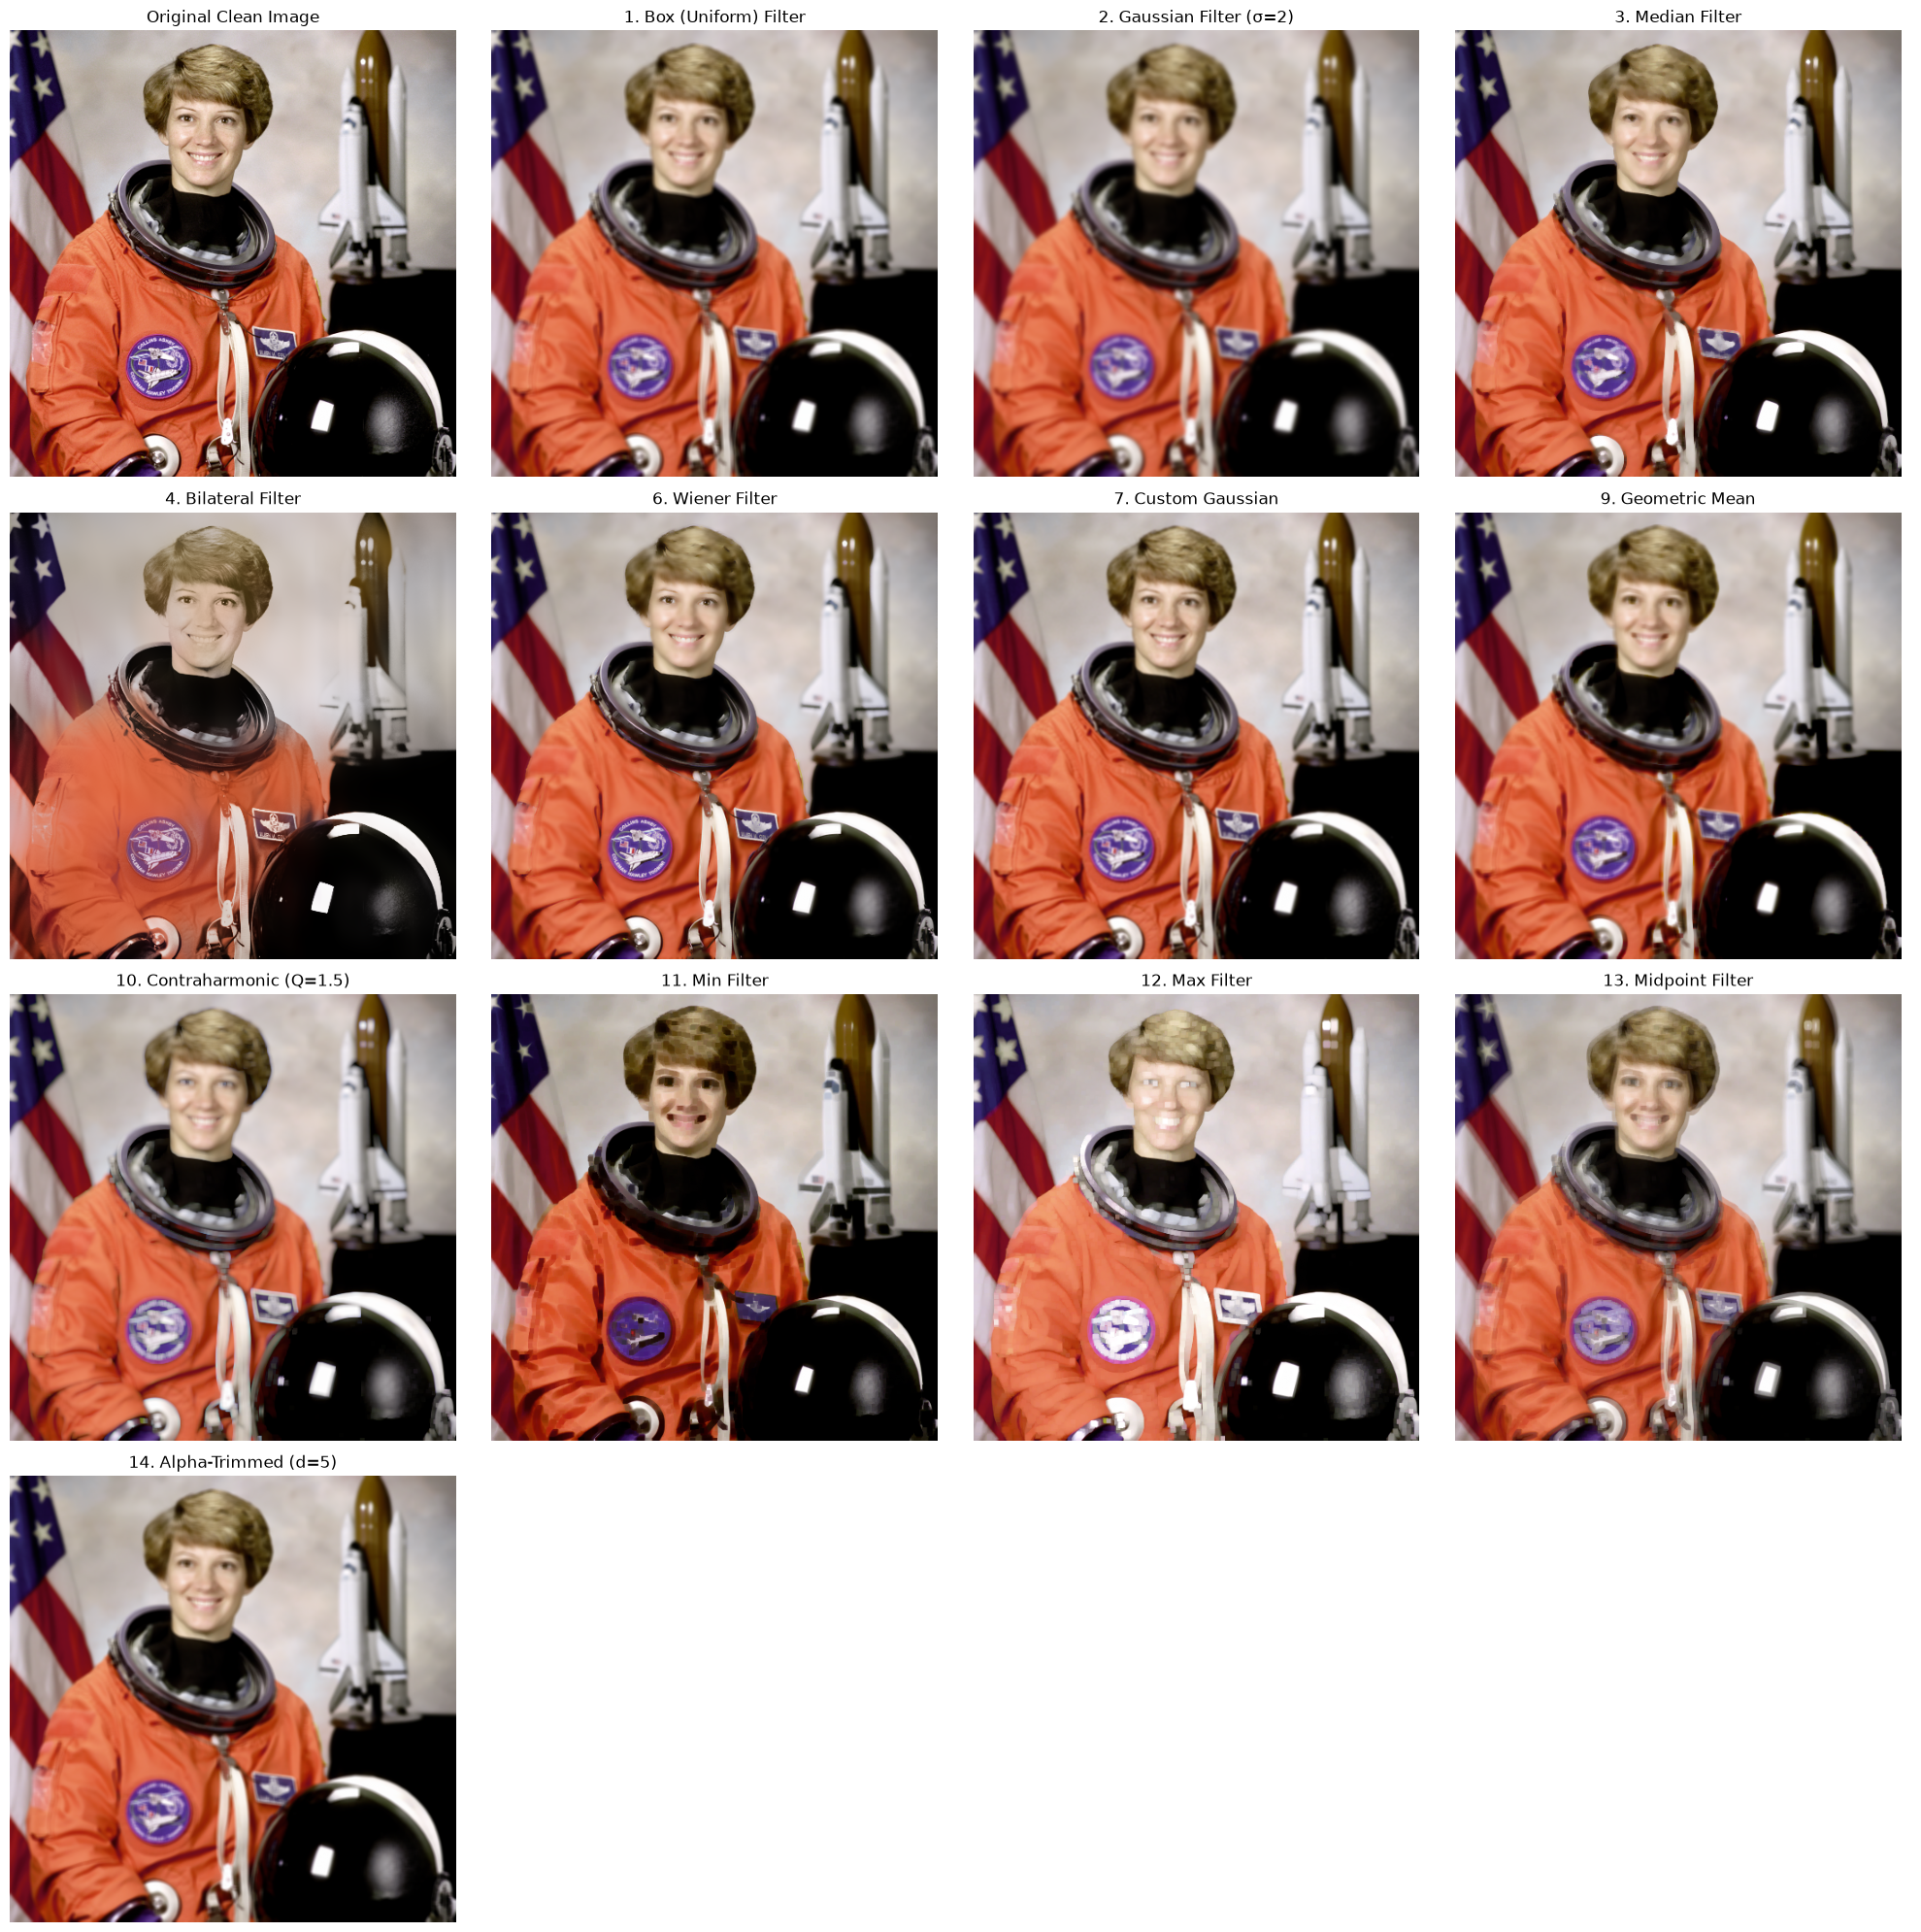

In [9]:
# --- Image Preparation ---
# Load a sample image and convert it to float format [0, 1]
original_image = img_as_float(data.astronaut())
# The noisy image is no longer created or used. All filters are applied to 'original_image'.


# --- Filter Implementations on the Original Image ---

# 1. Uniform (Box) Filter
box_filtered = uniform_filter(original_image, size=(5, 5, 1))

# 2. Gaussian Filter (sigma=2)
gaussian_filtered = gaussian_filter(original_image, sigma=(2, 2, 0))

# 3. Median Filter
median_filtered = np.zeros_like(original_image)
for i in range(3):
    median_filtered[..., i] = median_filter(original_image[..., i], size=5)

# 4. Bilateral Filter
bilateral_filtered = denoise_bilateral(original_image, sigma_color=0.1, sigma_spatial=15, channel_axis=-1)

# 5. Average Filter (via convolution)
def average_filter(image, kernel_size=5):
    kernel = np.ones((kernel_size, kernel_size)) / (kernel_size ** 2)
    filtered = np.zeros_like(image)
    for i in range(3):
        filtered[..., i] = convolve2d(image[..., i], kernel, mode='same', boundary='symm')
    return filtered
avg_filtered = average_filter(original_image, kernel_size=5)

# 6. Wiener Filter
wiener_filtered = np.zeros_like(original_image)
for i in range(3):
    wiener_filtered[..., i] = wiener(original_image[..., i], (5, 5))

# 7. Custom Gaussian Kernel Filter
def gaussian_kernel(size=5, sigma=1):
    ax = np.arange(-size // 2 + 1., size // 2 + 1.)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx**2 + yy**2) / (2. * sigma**2))
    return kernel / np.sum(kernel)
kernel = gaussian_kernel(5, sigma=1)
custom_gaussian_filtered = np.zeros_like(original_image)
for i in range(3):
    custom_gaussian_filtered[..., i] = convolve2d(original_image[..., i], kernel, mode='same', boundary='symm')

# 8. Arithmetic Mean Filter
arithmetic_mean_filtered = uniform_filter(original_image, size=(5, 5, 1))

# 9. Geometric Mean Filter
def geometric_mean_filter(image, size=5):
    return generic_filter(image, lambda x: np.prod(x + 1e-6)**(1.0/len(x)), size=size)
geo_mean_filtered = geometric_mean_filter(original_image, size=(5, 5, 1))

# 10. Contraharmonic Mean Filter
def contraharmonic_mean_filter(image, size, Q):
    image_64 = image.astype(np.float64)
    numerator = np.power(image_64, Q + 1)
    denominator = np.power(image_64, Q)
    kernel = np.ones((size, size))
    num_filtered = np.zeros_like(image_64)
    den_filtered = np.zeros_like(image_64)
    for i in range(3):
        num_filtered[..., i] = convolve2d(numerator[..., i], kernel, mode='same', boundary='symm')
        den_filtered[..., i] = convolve2d(denominator[..., i], kernel, mode='same', boundary='symm')
    return (num_filtered / (den_filtered + 1e-6)).astype(np.float32)
contra_harmonic_filtered = contraharmonic_mean_filter(original_image, 5, Q=1.5)

# 11. Min Filter
min_filtered = minimum_filter(original_image, size=(5, 5, 1))

# 12. Max Filter
max_filtered = maximum_filter(original_image, size=(5, 5, 1))

# 13. Midpoint Filter
def midpoint_filter(image, size=5):
    min_f = minimum_filter(image, size=(size, size, 1))
    max_f = maximum_filter(image, size=(size, size, 1))
    return (min_f + max_f) / 2
midpoint_filtered = midpoint_filter(original_image, size=5)

# 14. Alpha-Trimmed Mean Filter
def alpha_trimmed_mean_filter(image, size, d):
    if d < 0 or d >= np.prod(size):
        raise ValueError("d must be a non-negative integer less than the window size.")
    
    def _trim_mean(arr):
        arr_sorted = np.sort(arr)
        trimmed_arr = arr_sorted[d//2:-d//2] if d > 0 else arr_sorted
        return np.mean(trimmed_arr)
        
    return generic_filter(image, _trim_mean, size=size)
alpha_trimmed_filtered = alpha_trimmed_mean_filter(original_image, size=(5, 5, 1), d=5)


# --- Plotting the results ---
fig, axs = plt.subplots(4, 4, figsize=(20, 20))
axs = axs.ravel()

images = [
    (original_image, 'Original Clean Image'),
    (box_filtered, '1. Box (Uniform) Filter'),
    (gaussian_filtered, '2. Gaussian Filter (σ=2)'),
    (median_filtered, '3. Median Filter'),
    (bilateral_filtered, '4. Bilateral Filter'),
    (wiener_filtered, '6. Wiener Filter'),
    (custom_gaussian_filtered, '7. Custom Gaussian'),
    (geo_mean_filtered, '9. Geometric Mean'),
    (contra_harmonic_filtered, '10. Contraharmonic (Q=1.5)'),
    (min_filtered, '11. Min Filter'),
    (max_filtered, '12. Max Filter'),
    (midpoint_filtered, '13. Midpoint Filter'),
    (alpha_trimmed_filtered, '14. Alpha-Trimmed (d=5)'),
]

# Disable any unused subplots
for i in range(len(axs)):
    axs[i].axis('off') # Turn off all axes first
    if i < len(images):
        img, title = images[i]
        axs[i].imshow(np.clip(img, 0, 1))
        axs[i].set_title(title)

plt.tight_layout()
plt.show()